In [1]:
!pip install -q ucimlrepo

from ucimlrepo import fetch_ucirepo
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Load UCI Automobile dataset
automobile = fetch_ucirepo(id=10)

X = automobile.data.features
y = automobile.data.targets

df = pd.concat([X, y], axis=1)

print("Dataset loaded successfully")
print("Dataset shape:", df.shape)
print("\nColumns:")
print(df.columns.tolist())

Dataset loaded successfully
Dataset shape: (205, 26)

Columns:
['price', 'highway-mpg', 'city-mpg', 'peak-rpm', 'horsepower', 'compression-ratio', 'stroke', 'bore', 'fuel-system', 'engine-size', 'num-of-cylinders', 'engine-type', 'curb-weight', 'height', 'width', 'length', 'wheel-base', 'engine-location', 'drive-wheels', 'body-style', 'num-of-doors', 'aspiration', 'fuel-type', 'make', 'normalized-losses', 'symboling']


In [2]:
# Save the raw dataset locally
df.to_csv("automobile_week4_raw_dataset.csv", index=False)

print("Raw dataset saved successfully")
print("File name: automobile_week4_raw_dataset.csv")

Raw dataset saved successfully
File name: automobile_week4_raw_dataset.csv


In [3]:
# Initial dataset inspection

print("Dataset shape:", df.shape)

print("\nData types:")
print(df.dtypes)

print("\nMissing values:")
print(df.isnull().sum())

print("\nDuplicate rows:", df.duplicated().sum())

print("\nFirst 5 rows:")
display(df.head())

Dataset shape: (205, 26)

Data types:
price                float64
highway-mpg            int64
city-mpg               int64
peak-rpm             float64
horsepower           float64
compression-ratio    float64
stroke               float64
bore                 float64
fuel-system           object
engine-size            int64
num-of-cylinders       int64
engine-type           object
curb-weight            int64
height               float64
width                float64
length               float64
wheel-base           float64
engine-location       object
drive-wheels          object
body-style            object
num-of-doors         float64
aspiration            object
fuel-type             object
make                  object
normalized-losses    float64
symboling              int64
dtype: object

Missing values:
price                 4
highway-mpg           0
city-mpg              0
peak-rpm              2
horsepower            2
compression-ratio     0
stroke                4
bore     

,price,highway-mpg,city-mpg,peak-rpm,horsepower,compression-ratio,stroke,bore,fuel-system,engine-size,...,wheel-base,engine-location,drive-wheels,body-style,num-of-doors,aspiration,fuel-type,make,normalized-losses,symboling
0,13495.0,27,21,5000.0,111.0,9.0,2.68,3.47,mpfi,130,...,88.6,front,rwd,convertible,2.0,std,gas,alfa-romero,NaN,3
1,16500.0,27,21,5000.0,111.0,9.0,2.68,3.47,mpfi,130,...,88.6,front,rwd,convertible,2.0,std,gas,alfa-romero,NaN,3
2,16500.0,26,19,5000.0,154.0,9.0,3.47,2.68,mpfi,152,...,94.5,front,rwd,hatchback,2.0,std,gas,alfa-romero,NaN,1
3,13950.0,30,24,5500.0,102.0,10.0,3.40,3.19,mpfi,109,...,99.8,front,fwd,sedan,4.0,std,gas,audi,164.0,2
4,17450.0,22,18,5500.0,115.0,8.0,3.40,3.19,mpfi,136,...,99.4,front,4wd,sedan,4.0,std,gas,audi,164.0,2


In [4]:
# Create a separate copy for Week 4 analysis

viz_df = df.copy()

print("Visualization dataframe created")
print("Shape:", viz_df.shape)

Visualization dataframe created
Shape: (205, 26)


In [5]:
# Numerical correlation analysis

numeric_df = viz_df.select_dtypes(include=np.number)

correlation_matrix = numeric_df.corr()

print("Numerical variables:", len(numeric_df.columns))
print("\nCorrelation with automobile price:")
print(
    correlation_matrix["price"]
    .sort_values(ascending=False)
)

Numerical variables: 18

Correlation with automobile price:
price                1.000000
engine-size          0.872335
curb-weight          0.834415
horsepower           0.810533
width                0.751265
num-of-cylinders     0.708645
length               0.690628
wheel-base           0.584642
bore                 0.543436
normalized-losses    0.203254
height               0.135486
stroke               0.082310
compression-ratio    0.071107
num-of-doors         0.046532
symboling           -0.082391
peak-rpm            -0.101649
city-mpg            -0.686571
highway-mpg         -0.704692
Name: price, dtype: float64


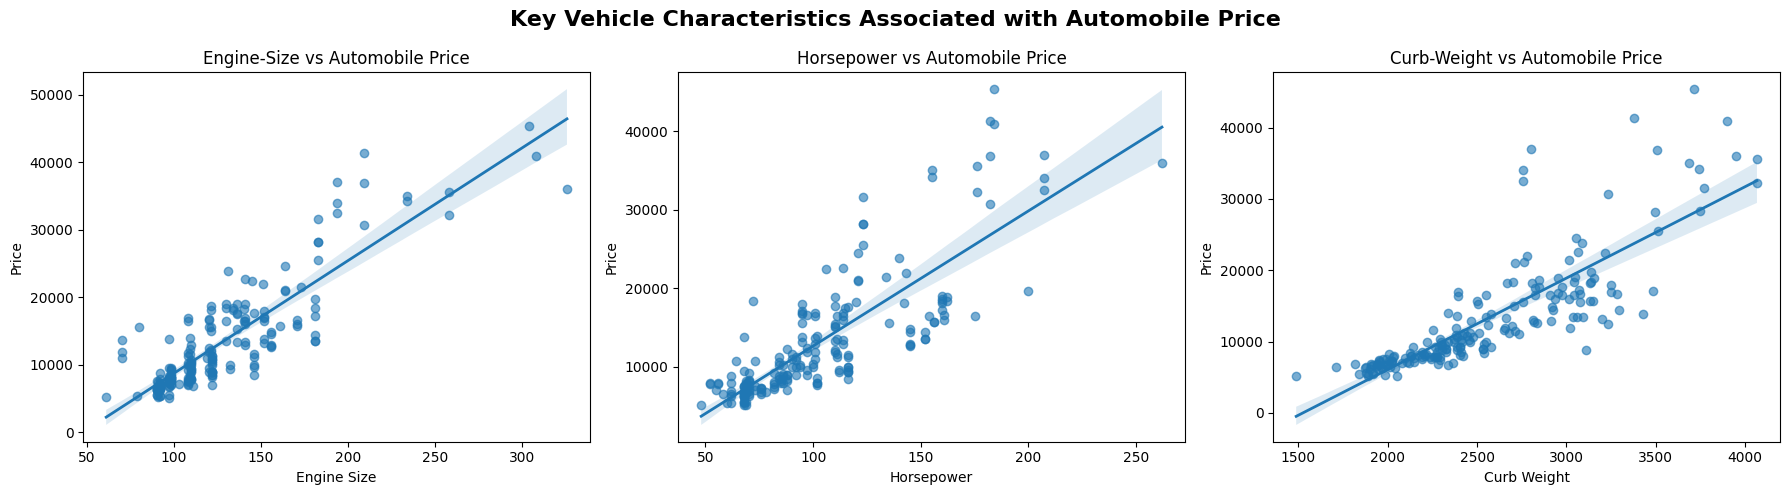

In [6]:
# Advanced Visualization 1:
# Relationship between vehicle characteristics and price

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

features = ["engine-size", "horsepower", "curb-weight"]

for ax, feature in zip(axes, features):
    sns.regplot(
        data=viz_df,
        x=feature,
        y="price",
        scatter_kws={"alpha": 0.6},
        line_kws={"linewidth": 2},
        ax=ax
    )
    ax.set_title(f"{feature.title()} vs Automobile Price")
    ax.set_xlabel(feature.replace("-", " ").title())
    ax.set_ylabel("Price")

plt.suptitle(
    "Key Vehicle Characteristics Associated with Automobile Price",
    fontsize=16,
    fontweight="bold"
)

plt.tight_layout()
plt.show()

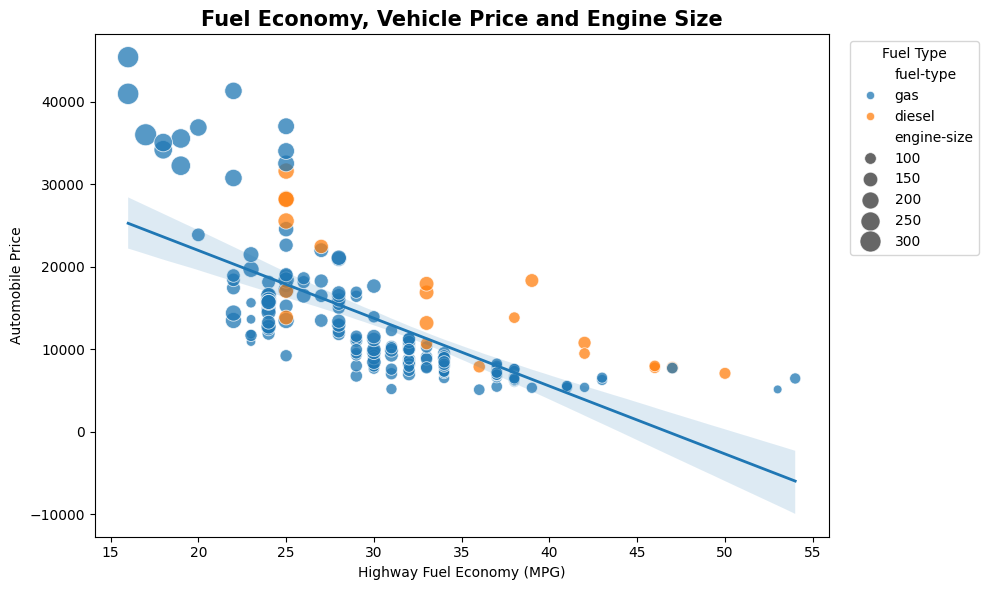

In [7]:
# Advanced Visualization 2:
# Fuel economy versus automobile price

plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=viz_df,
    x="highway-mpg",
    y="price",
    hue="fuel-type",
    size="engine-size",
    sizes=(40, 250),
    alpha=0.75
)

sns.regplot(
    data=viz_df,
    x="highway-mpg",
    y="price",
    scatter=False,
    line_kws={"linewidth": 2}
)

plt.title(
    "Fuel Economy, Vehicle Price and Engine Size",
    fontsize=15,
    fontweight="bold"
)

plt.xlabel("Highway Fuel Economy (MPG)")
plt.ylabel("Automobile Price")
plt.legend(title="Fuel Type", bbox_to_anchor=(1.02, 1), loc="upper left")

plt.tight_layout()
plt.show()

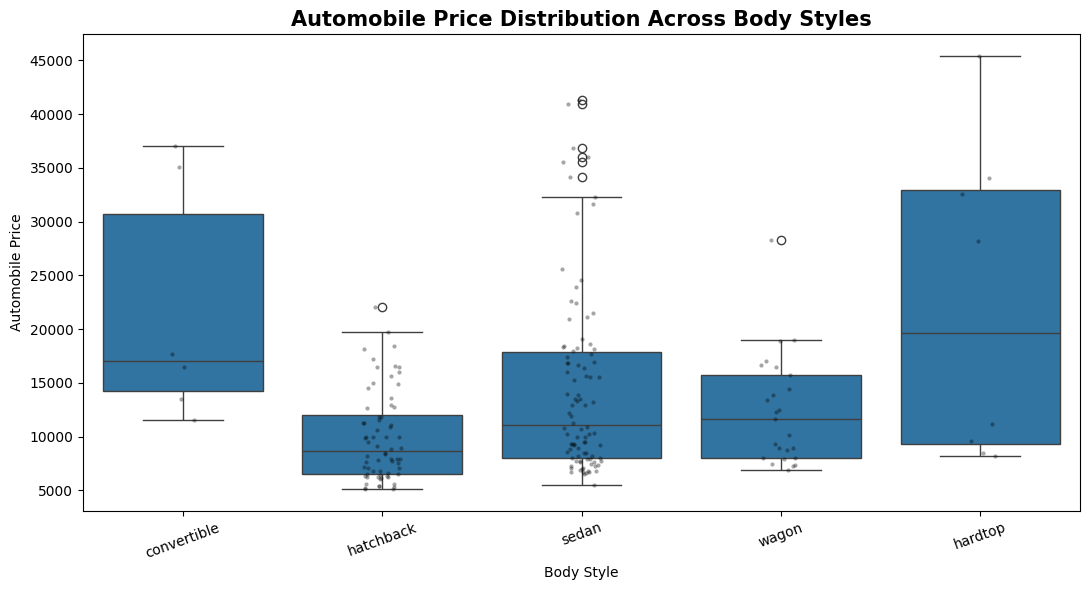

In [8]:
# Advanced Visualization 3:
# Price distribution across vehicle body styles

plt.figure(figsize=(11, 6))

sns.boxplot(
    data=viz_df,
    x="body-style",
    y="price"
)

sns.stripplot(
    data=viz_df,
    x="body-style",
    y="price",
    color="black",
    alpha=0.35,
    size=3
)

plt.title(
    "Automobile Price Distribution Across Body Styles",
    fontsize=15,
    fontweight="bold"
)

plt.xlabel("Body Style")
plt.ylabel("Automobile Price")

plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

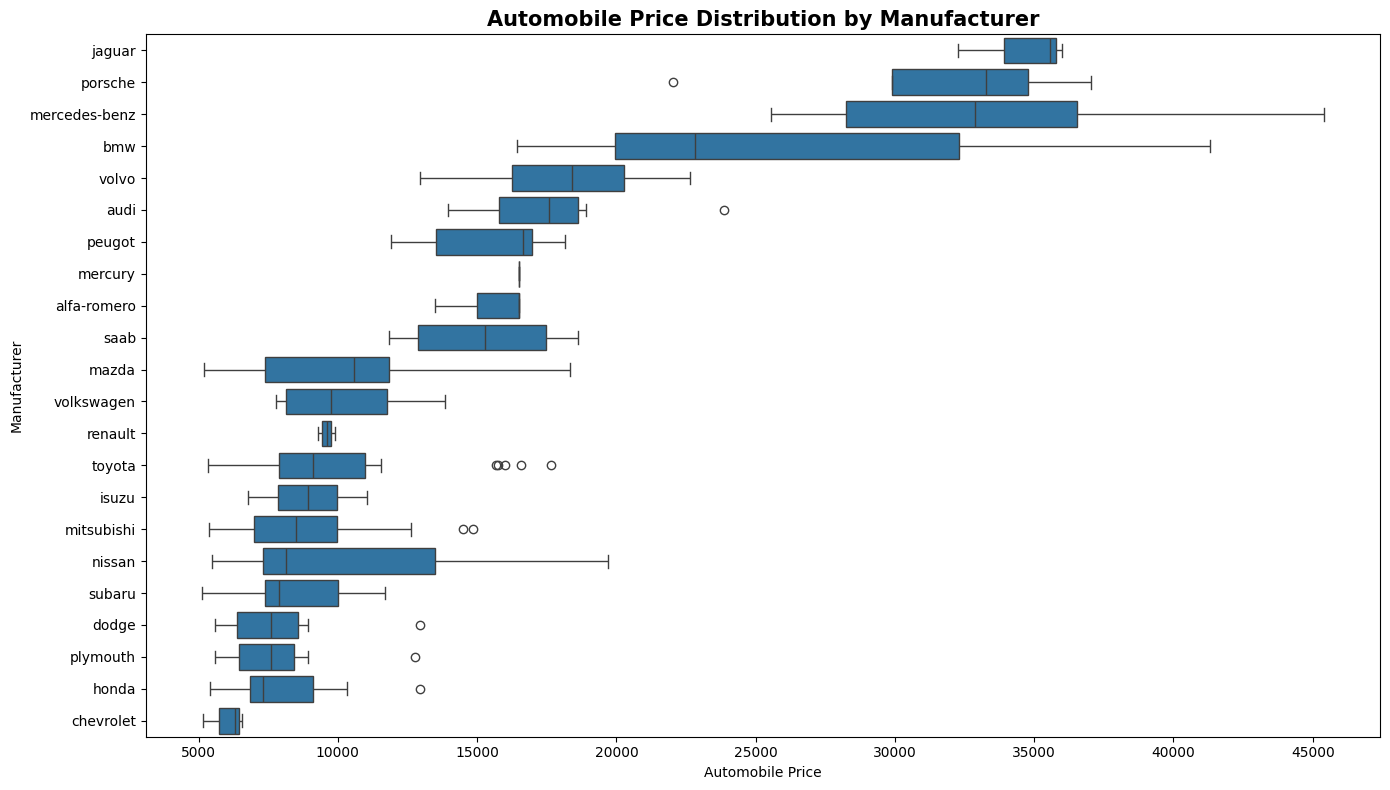

In [9]:
# Advanced Visualization 4:
# Manufacturer price positioning

manufacturer_order = (
    viz_df.groupby("make")["price"]
    .median()
    .sort_values(ascending=False)
    .index
)

plt.figure(figsize=(14, 8))

sns.boxplot(
    data=viz_df,
    x="price",
    y="make",
    order=manufacturer_order
)

plt.title(
    "Automobile Price Distribution by Manufacturer",
    fontsize=15,
    fontweight="bold"
)

plt.xlabel("Automobile Price")
plt.ylabel("Manufacturer")

plt.tight_layout()
plt.show()

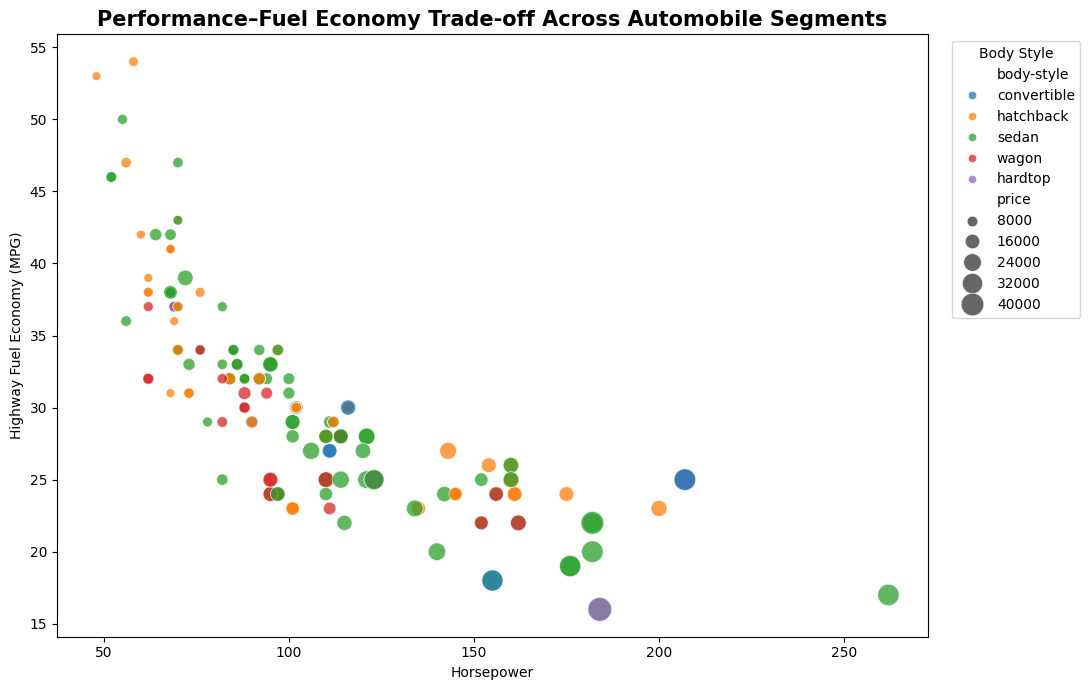

In [10]:
# Advanced Visualization 5:
# Performance versus fuel economy

plt.figure(figsize=(11, 7))

sns.scatterplot(
    data=viz_df,
    x="horsepower",
    y="highway-mpg",
    hue="body-style",
    size="price",
    sizes=(40, 300),
    alpha=0.75
)

plt.title(
    "Performance–Fuel Economy Trade-off Across Automobile Segments",
    fontsize=15,
    fontweight="bold"
)

plt.xlabel("Horsepower")
plt.ylabel("Highway Fuel Economy (MPG)")

plt.legend(
    title="Body Style",
    bbox_to_anchor=(1.02, 1),
    loc="upper left"
)

plt.tight_layout()
plt.show()

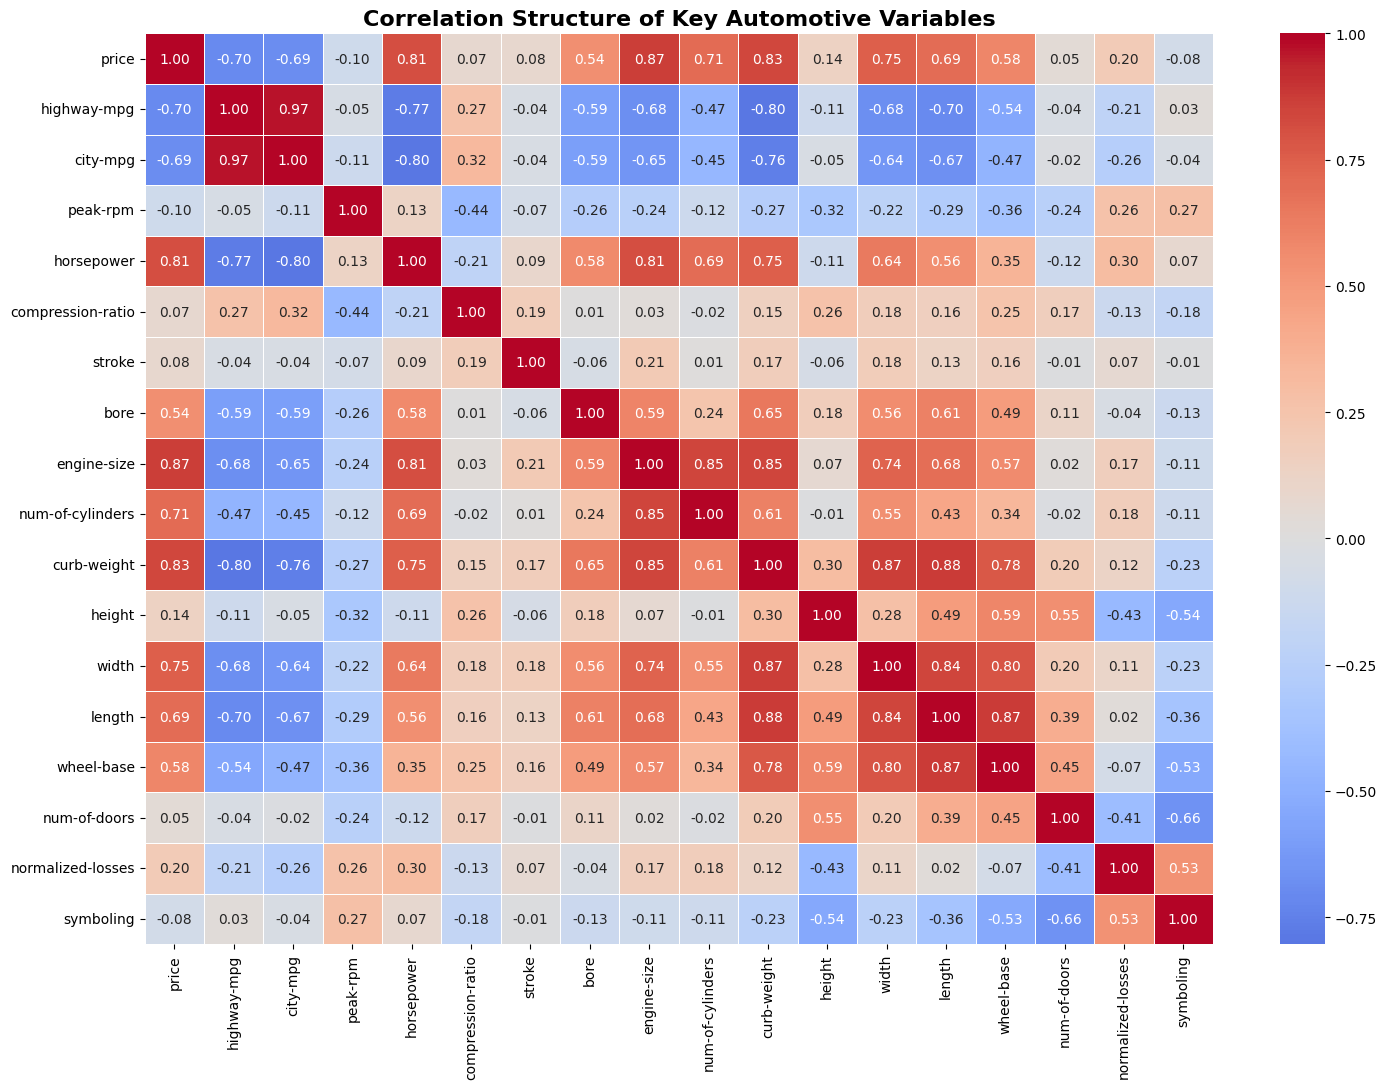

In [11]:
# Advanced Visualization 6:
# Correlation heatmap of numerical automotive variables

plt.figure(figsize=(15, 11))

sns.heatmap(
    correlation_matrix,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0,
    linewidths=0.5
)

plt.title(
    "Correlation Structure of Key Automotive Variables",
    fontsize=16,
    fontweight="bold"
)

plt.tight_layout()
plt.show()

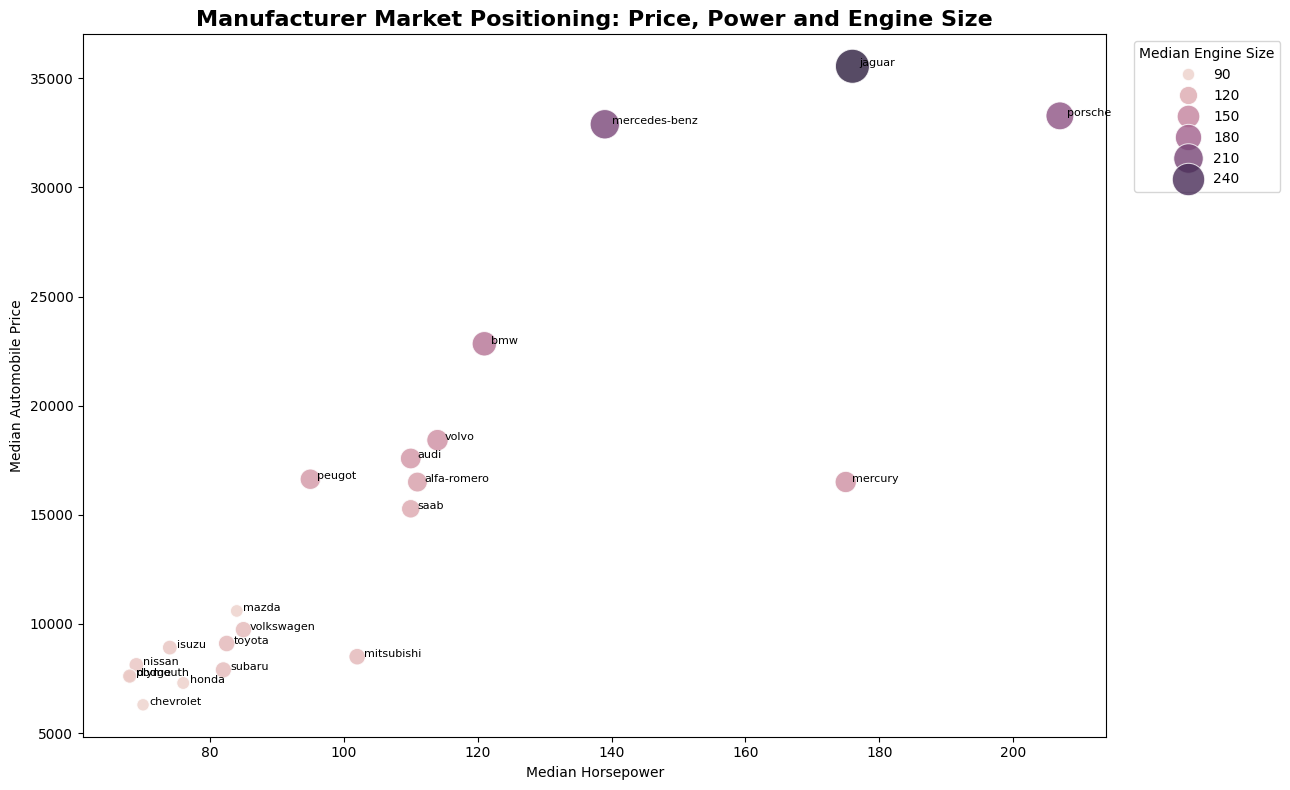

In [12]:
# Advanced Visualization 7:
# Manufacturer positioning by price and performance

manufacturer_summary = (
    viz_df.groupby("make")
    .agg(
        median_price=("price", "median"),
        median_horsepower=("horsepower", "median"),
        median_engine_size=("engine-size", "median"),
        vehicle_count=("make", "size")
    )
    .reset_index()
)

plt.figure(figsize=(13, 8))

sns.scatterplot(
    data=manufacturer_summary,
    x="median_horsepower",
    y="median_price",
    size="median_engine_size",
    hue="median_engine_size",
    sizes=(80, 600),
    alpha=0.8
)

for _, row in manufacturer_summary.iterrows():
    plt.text(
        row["median_horsepower"] + 1,
        row["median_price"],
        row["make"],
        fontsize=8
    )

plt.title(
    "Manufacturer Market Positioning: Price, Power and Engine Size",
    fontsize=16,
    fontweight="bold"
)

plt.xlabel("Median Horsepower")
plt.ylabel("Median Automobile Price")

plt.legend(
    title="Median Engine Size",
    bbox_to_anchor=(1.02, 1),
    loc="upper left"
)

plt.tight_layout()
plt.show()

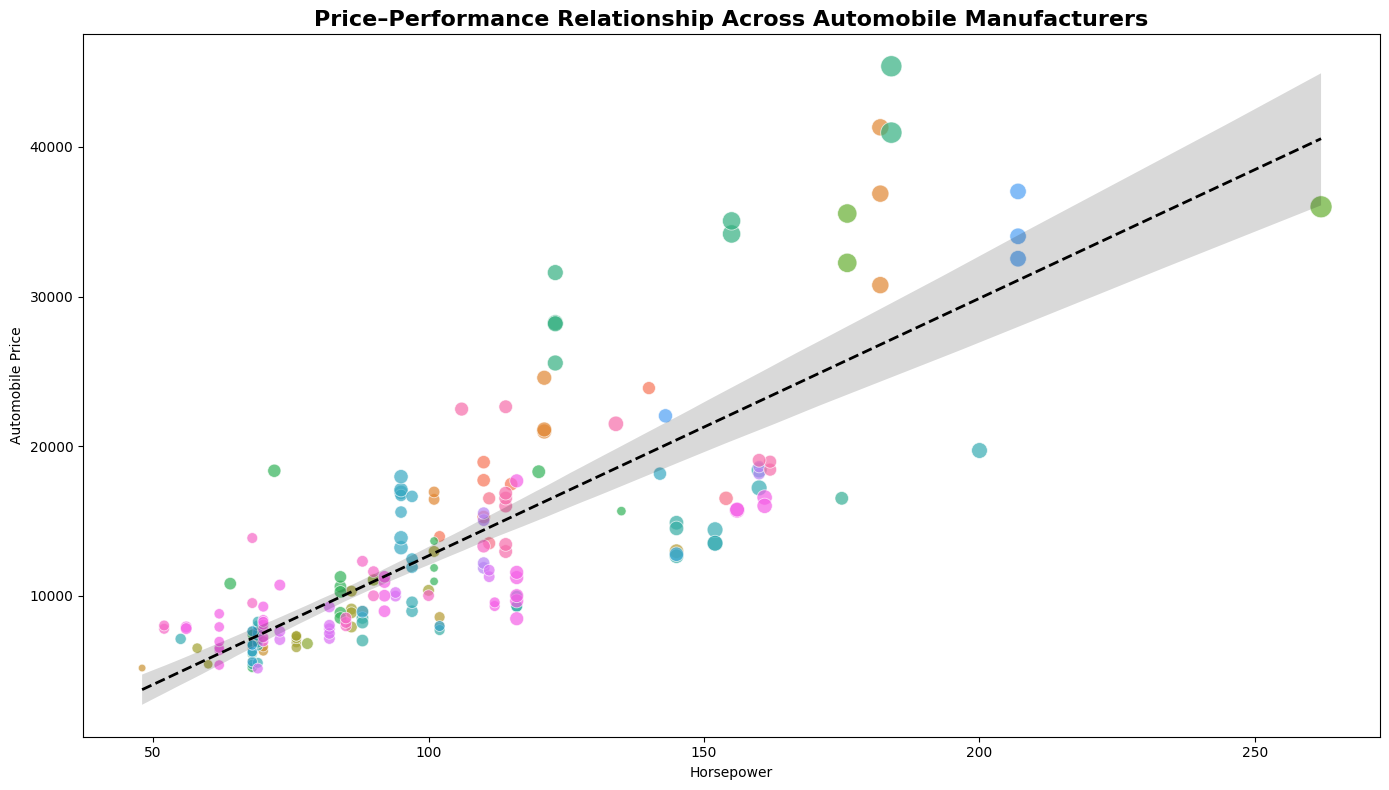

In [13]:
# Advanced Visualization 8:
# Price-performance positioning by manufacturer

plt.figure(figsize=(14, 8))

sns.scatterplot(
    data=viz_df,
    x="horsepower",
    y="price",
    hue="make",
    size="engine-size",
    sizes=(30, 250),
    alpha=0.7,
    legend=False
)

sns.regplot(
    data=viz_df,
    x="horsepower",
    y="price",
    scatter=False,
    color="black",
    line_kws={"linewidth": 2, "linestyle": "--"}
)

plt.title(
    "Price–Performance Relationship Across Automobile Manufacturers",
    fontsize=16,
    fontweight="bold"
)

plt.xlabel("Horsepower")
plt.ylabel("Automobile Price")

plt.tight_layout()
plt.show()

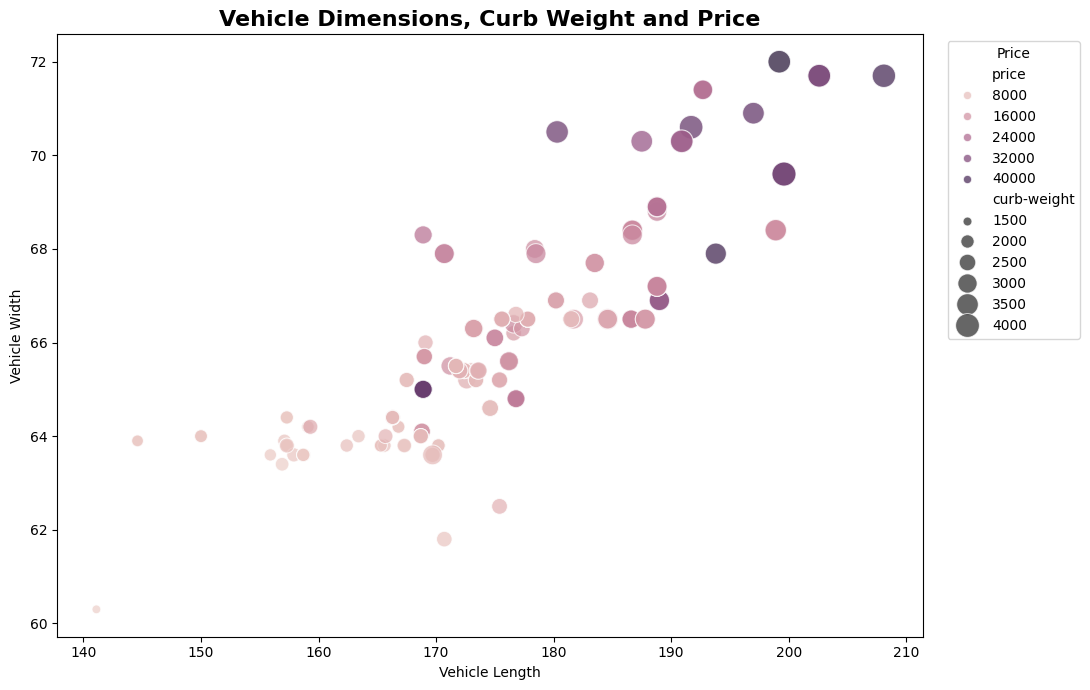

In [14]:
# Advanced Visualization 9:
# Vehicle dimensions, weight and price

plt.figure(figsize=(11, 7))

sns.scatterplot(
    data=viz_df,
    x="length",
    y="width",
    hue="price",
    size="curb-weight",
    sizes=(40, 300),
    alpha=0.75
)

plt.title(
    "Vehicle Dimensions, Curb Weight and Price",
    fontsize=16,
    fontweight="bold"
)

plt.xlabel("Vehicle Length")
plt.ylabel("Vehicle Width")

plt.legend(
    title="Price",
    bbox_to_anchor=(1.02, 1),
    loc="upper left"
)

plt.tight_layout()
plt.show()

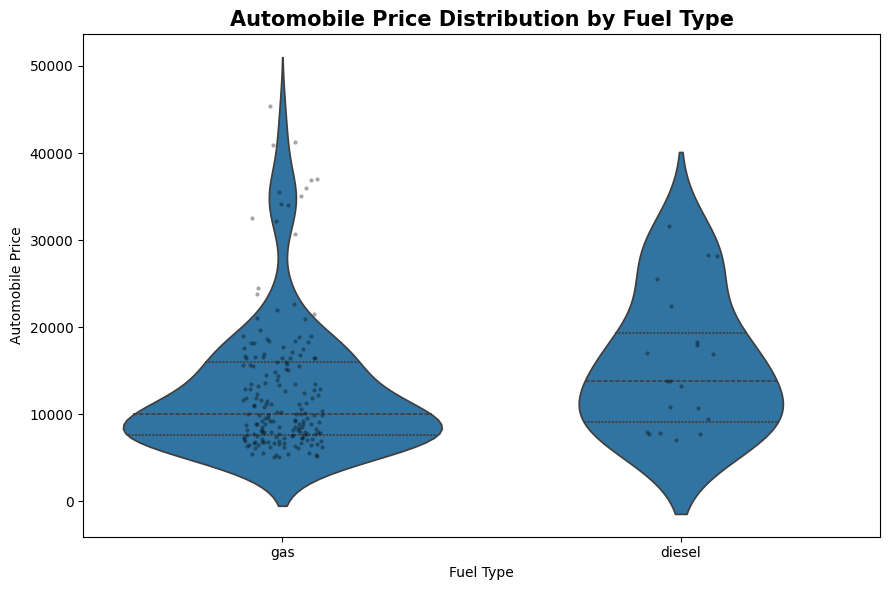

In [15]:
# Advanced Visualization 10:
# Price distribution by fuel type

plt.figure(figsize=(9, 6))

sns.violinplot(
    data=viz_df,
    x="fuel-type",
    y="price",
    inner="quartile"
)

sns.stripplot(
    data=viz_df,
    x="fuel-type",
    y="price",
    color="black",
    alpha=0.35,
    size=3
)

plt.title(
    "Automobile Price Distribution by Fuel Type",
    fontsize=15,
    fontweight="bold"
)

plt.xlabel("Fuel Type")
plt.ylabel("Automobile Price")

plt.tight_layout()
plt.show()

In [16]:
# Advanced Visualization 11:
# Vehicle characteristics across price segments

analysis_df = viz_df.dropna(subset=["price"]).copy()

analysis_df["price_segment"] = pd.qcut(
    analysis_df["price"],
    q=4,
    labels=["Budget", "Lower-Mid", "Upper-Mid", "Premium"]
)

segment_summary = (
    analysis_df.groupby("price_segment", observed=False)
    .agg(
        median_price=("price", "median"),
        median_horsepower=("horsepower", "median"),
        median_engine_size=("engine-size", "median"),
        median_curb_weight=("curb-weight", "median"),
        median_highway_mpg=("highway-mpg", "median"),
        vehicle_count=("price", "size")
    )
    .reset_index()
)

display(segment_summary)

,price_segment,median_price,median_horsepower,median_engine_size,median_curb_weight,median_highway_mpg,vehicle_count
0,Budget,6785.0,68.0,92.0,1985.0,38.0,51
1,Lower-Mid,8883.0,86.0,109.5,2311.5,32.0,50
2,Upper-Mid,13082.0,110.0,122.0,2687.0,27.5,50
3,Premium,20334.5,141.0,158.0,3073.0,25.0,50


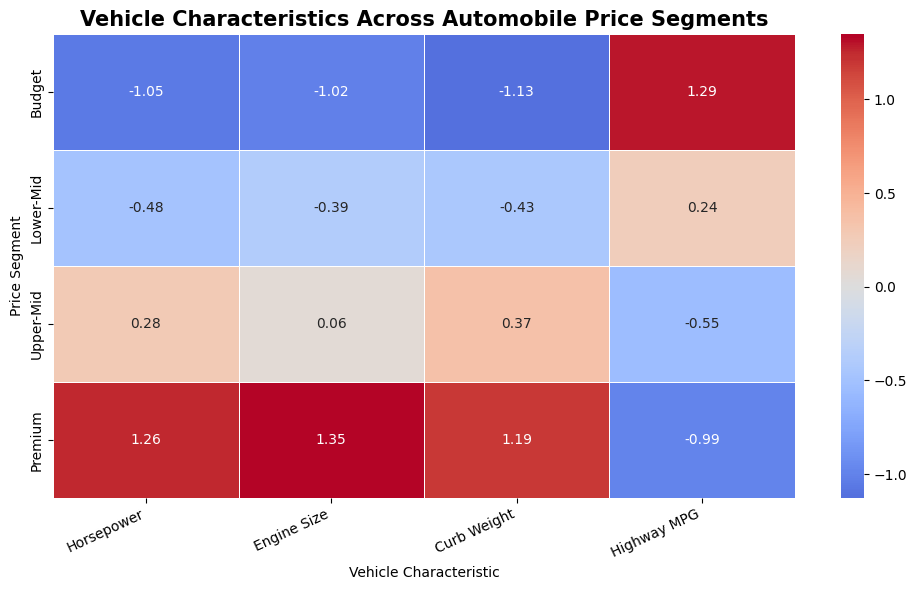

In [17]:
# Advanced Visualization 12:
# Price-segment vehicle profile heatmap

heatmap_data = segment_summary.set_index("price_segment")[
    [
        "median_horsepower",
        "median_engine_size",
        "median_curb_weight",
        "median_highway_mpg"
    ]
].copy()

# Standardize each variable so different measurement scales can be compared
heatmap_z = (heatmap_data - heatmap_data.mean()) / heatmap_data.std()

plt.figure(figsize=(10, 6))

sns.heatmap(
    heatmap_z,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0,
    linewidths=0.5
)

plt.title(
    "Vehicle Characteristics Across Automobile Price Segments",
    fontsize=15,
    fontweight="bold"
)

plt.xlabel("Vehicle Characteristic")
plt.ylabel("Price Segment")

plt.xticks(
    ticks=np.arange(4) + 0.5,
    labels=[
        "Horsepower",
        "Engine Size",
        "Curb Weight",
        "Highway MPG"
    ],
    rotation=25,
    ha="right"
)

plt.tight_layout()
plt.show()

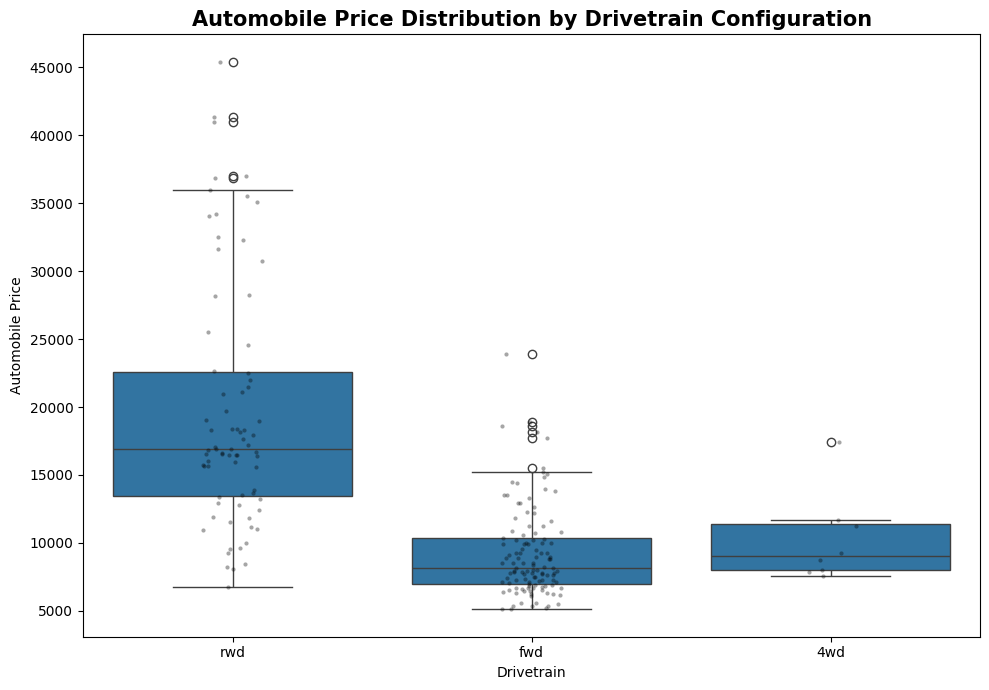

In [18]:
# Advanced Visualization 13:
# Drivetrain configuration and price positioning

plt.figure(figsize=(10, 7))

sns.boxplot(
    data=viz_df,
    x="drive-wheels",
    y="price"
)

sns.stripplot(
    data=viz_df,
    x="drive-wheels",
    y="price",
    color="black",
    alpha=0.35,
    size=3
)

plt.title(
    "Automobile Price Distribution by Drivetrain Configuration",
    fontsize=15,
    fontweight="bold"
)

plt.xlabel("Drivetrain")
plt.ylabel("Automobile Price")

plt.tight_layout()
plt.show()

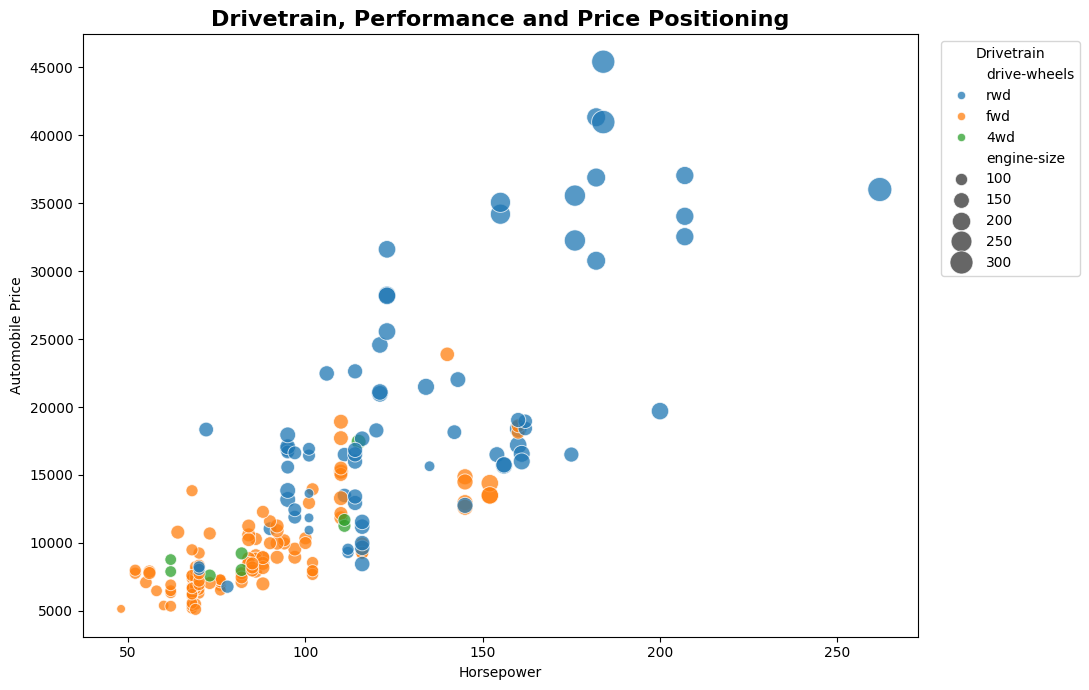

In [19]:
# Advanced Visualization 14:
# Drivetrain, performance and price positioning

plt.figure(figsize=(11, 7))

sns.scatterplot(
    data=viz_df,
    x="horsepower",
    y="price",
    hue="drive-wheels",
    size="engine-size",
    sizes=(40, 300),
    alpha=0.75
)

plt.title(
    "Drivetrain, Performance and Price Positioning",
    fontsize=16,
    fontweight="bold"
)

plt.xlabel("Horsepower")
plt.ylabel("Automobile Price")

plt.legend(
    title="Drivetrain",
    bbox_to_anchor=(1.02, 1),
    loc="upper left"
)

plt.tight_layout()
plt.show()

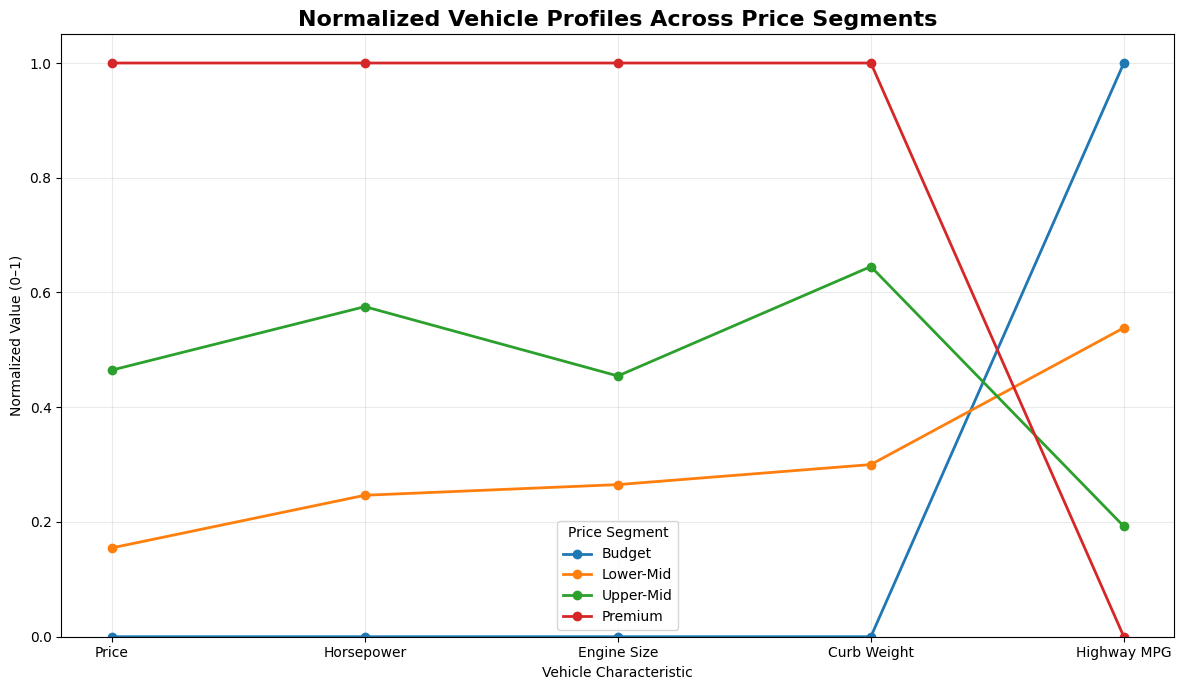

In [20]:
# Advanced Visualization 15:
# Overall automotive market-segment profile

profile_data = segment_summary[
    [
        "price_segment",
        "median_price",
        "median_horsepower",
        "median_engine_size",
        "median_curb_weight",
        "median_highway_mpg"
    ]
].copy()

# Normalize each metric to a 0–1 scale
metrics = [
    "median_price",
    "median_horsepower",
    "median_engine_size",
    "median_curb_weight",
    "median_highway_mpg"
]

for column in metrics:
    min_value = profile_data[column].min()
    max_value = profile_data[column].max()
    profile_data[column] = (
        (profile_data[column] - min_value)
        / (max_value - min_value)
    )

profile_plot = profile_data.set_index("price_segment")

profile_plot.columns = [
    "Price",
    "Horsepower",
    "Engine Size",
    "Curb Weight",
    "Highway MPG"
]

plt.figure(figsize=(12, 7))

for segment in profile_plot.index:
    plt.plot(
        profile_plot.columns,
        profile_plot.loc[segment],
        marker="o",
        linewidth=2,
        label=segment
    )

plt.title(
    "Normalized Vehicle Profiles Across Price Segments",
    fontsize=16,
    fontweight="bold"
)

plt.ylabel("Normalized Value (0–1)")
plt.xlabel("Vehicle Characteristic")
plt.ylim(0, 1.05)

plt.legend(title="Price Segment")
plt.grid(alpha=0.25)

plt.tight_layout()
plt.show()

In [21]:
# Advanced Visualization 16:
# Interactive manufacturer market-positioning visualization

import plotly.express as px

interactive_manufacturer = manufacturer_summary.copy()

fig = px.scatter(
    interactive_manufacturer,
    x="median_horsepower",
    y="median_price",
    size="median_engine_size",
    color="median_engine_size",
    hover_name="make",
    hover_data={
        "median_price": ":,.0f",
        "median_horsepower": ":.0f",
        "median_engine_size": ":.0f",
        "vehicle_count": True
    },
    labels={
        "median_horsepower": "Median Horsepower",
        "median_price": "Median Price",
        "median_engine_size": "Median Engine Size"
    },
    title="Interactive Manufacturer Market Positioning"
)

fig.update_layout(
    width=1000,
    height=650
)

fig.show()

In [22]:
# Key automotive statistics for interpretation

key_stats = {
    "Highest median-price manufacturer": manufacturer_summary.loc[
        manufacturer_summary["median_price"].idxmax(), "make"
    ],
    "Highest median manufacturer price": manufacturer_summary["median_price"].max(),
    "Highest median horsepower manufacturer": manufacturer_summary.loc[
        manufacturer_summary["median_horsepower"].idxmax(), "make"
    ],
    "Highest median horsepower": manufacturer_summary["median_horsepower"].max(),
    "Highest median engine-size manufacturer": manufacturer_summary.loc[
        manufacturer_summary["median_engine_size"].idxmax(), "make"
    ],
    "Highest median engine size": manufacturer_summary["median_engine_size"].max(),
}

for key, value in key_stats.items():
    print(f"{key}: {value}")

Highest median-price manufacturer: jaguar
Highest median manufacturer price: 35550.0
Highest median horsepower manufacturer: porsche
Highest median horsepower: 207.0
Highest median engine-size manufacturer: jaguar
Highest median engine size: 258.0


In [23]:
# Compare Budget and Premium vehicle profiles

budget = segment_summary[
    segment_summary["price_segment"] == "Budget"
].iloc[0]

premium = segment_summary[
    segment_summary["price_segment"] == "Premium"
].iloc[0]

print("BUDGET vs PREMIUM COMPARISON")
print("-" * 40)

print(f"Median price:")
print(f"  Budget  : ₹{budget['median_price']:,.2f}")
print(f"  Premium : ₹{premium['median_price']:,.2f}")

print(f"\nMedian horsepower:")
print(f"  Budget  : {budget['median_horsepower']:.1f} HP")
print(f"  Premium : {premium['median_horsepower']:.1f} HP")

print(f"\nMedian engine size:")
print(f"  Budget  : {budget['median_engine_size']:.1f}")
print(f"  Premium : {premium['median_engine_size']:.1f}")

print(f"\nMedian curb weight:")
print(f"  Budget  : {budget['median_curb_weight']:.1f}")
print(f"  Premium : {premium['median_curb_weight']:.1f}")

print(f"\nMedian highway MPG:")
print(f"  Budget  : {budget['median_highway_mpg']:.1f} MPG")
print(f"  Premium : {premium['median_highway_mpg']:.1f} MPG")

BUDGET vs PREMIUM COMPARISON
----------------------------------------
Median price:
  Budget  : ₹6,785.00
  Premium : ₹20,334.50

Median horsepower:
  Budget  : 68.0 HP
  Premium : 141.0 HP

Median engine size:
  Budget  : 92.0
  Premium : 158.0

Median curb weight:
  Budget  : 1985.0
  Premium : 3073.0

Median highway MPG:
  Budget  : 38.0 MPG
  Premium : 25.0 MPG


In [24]:
# Manufacturer price-positioning summary

highest_price_manufacturer = manufacturer_summary.loc[
    manufacturer_summary["median_price"].idxmax()
]

lowest_price_manufacturer = manufacturer_summary.loc[
    manufacturer_summary["median_price"].idxmin()
]

price_difference = (
    highest_price_manufacturer["median_price"]
    - lowest_price_manufacturer["median_price"]
)

print("MANUFACTURER PRICE POSITIONING")
print("-" * 40)

print(
    f"Highest median price: "
    f"{highest_price_manufacturer['make']} — "
    f"₹{highest_price_manufacturer['median_price']:,.2f}"
)

print(
    f"Lowest median price: "
    f"{lowest_price_manufacturer['make']} — "
    f"₹{lowest_price_manufacturer['median_price']:,.2f}"
)

print(
    f"\nDifference between highest and lowest median price: "
    f"₹{price_difference:,.2f}"
)

MANUFACTURER PRICE POSITIONING
----------------------------------------
Highest median price: jaguar — ₹35,550.00
Lowest median price: chevrolet — ₹6,295.00

Difference between highest and lowest median price: ₹29,255.00


In [25]:
# Performance–efficiency relationship

horsepower_mpg_corr = viz_df[
    ["horsepower", "highway-mpg"]
].corr().iloc[0, 1]

print("Performance–Efficiency Relationship")
print("-" * 40)
print(
    f"Correlation between horsepower and highway MPG: "
    f"{horsepower_mpg_corr:.3f}"
)

print("\nInterpretation:")
if horsepower_mpg_corr < 0:
    print(
        "The negative correlation indicates that higher-horsepower "
        "vehicles tend to have lower highway fuel economy in this dataset."
    )
else:
    print(
        "The relationship is not negative in this dataset."
    )

Performance–Efficiency Relationship
----------------------------------------
Correlation between horsepower and highway MPG: -0.771

Interpretation:
The negative correlation indicates that higher-horsepower vehicles tend to have lower highway fuel economy in this dataset.


In [26]:
# Consolidated automotive insight metrics

insight_metrics = pd.DataFrame({
    "Insight": [
        "Engine size vs price",
        "Curb weight vs price",
        "Horsepower vs price",
        "Highway MPG vs price",
        "City MPG vs price",
        "Horsepower vs highway MPG"
    ],
    "Correlation": [
        correlation_matrix.loc["engine-size", "price"],
        correlation_matrix.loc["curb-weight", "price"],
        correlation_matrix.loc["horsepower", "price"],
        correlation_matrix.loc["highway-mpg", "price"],
        correlation_matrix.loc["city-mpg", "price"],
        horsepower_mpg_corr
    ]
})

insight_metrics["Relationship Strength"] = insight_metrics["Correlation"].abs()

display(
    insight_metrics.sort_values(
        "Relationship Strength",
        ascending=False
    ).reset_index(drop=True)
)

,Insight,Correlation,Relationship Strength
0,Engine size vs price,0.872335,0.872335
1,Curb weight vs price,0.834415,0.834415
2,Horsepower vs price,0.810533,0.810533
3,Horsepower vs highway MPG,-0.770908,0.770908
4,Highway MPG vs price,-0.704692,0.704692
5,City MPG vs price,-0.686571,0.686571


In [27]:
# Percentage change from Budget to Premium segment

comparison_metrics = {
    "Price": (budget["median_price"], premium["median_price"]),
    "Horsepower": (budget["median_horsepower"], premium["median_horsepower"]),
    "Engine Size": (budget["median_engine_size"], premium["median_engine_size"]),
    "Curb Weight": (budget["median_curb_weight"], premium["median_curb_weight"]),
    "Highway MPG": (budget["median_highway_mpg"], premium["median_highway_mpg"])
}

print("BUDGET → PREMIUM PERCENTAGE CHANGE")
print("-" * 45)

for metric, (budget_value, premium_value) in comparison_metrics.items():
    percentage_change = (
        (premium_value - budget_value)
        / budget_value
    ) * 100

    print(
        f"{metric}: {percentage_change:+.1f}%"
    )

BUDGET → PREMIUM PERCENTAGE CHANGE
---------------------------------------------
Price: +199.7%
Horsepower: +107.4%
Engine Size: +71.7%
Curb Weight: +54.8%
Highway MPG: -34.2%


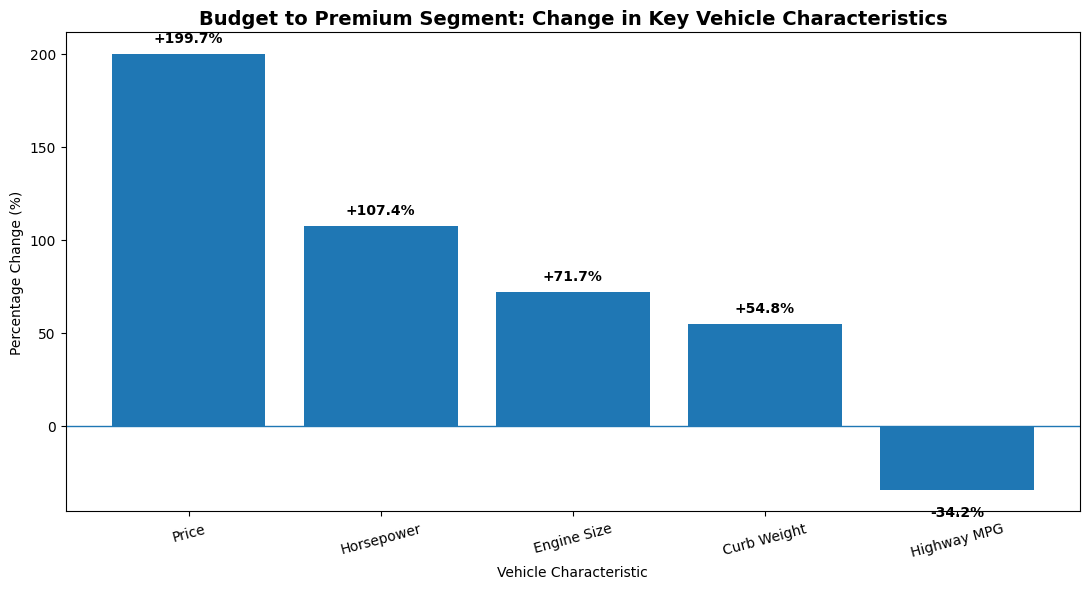

In [28]:
# Budget vs Premium: percentage change profile

percentage_changes = pd.DataFrame({
    "Metric": [
        "Price",
        "Horsepower",
        "Engine Size",
        "Curb Weight",
        "Highway MPG"
    ],
    "Percentage Change": [
        199.7,
        107.4,
        71.7,
        54.8,
        -34.2
    ]
})

plt.figure(figsize=(11, 6))

bars = plt.bar(
    percentage_changes["Metric"],
    percentage_changes["Percentage Change"]
)

plt.axhline(0, linewidth=1)

plt.title(
    "Budget to Premium Segment: Change in Key Vehicle Characteristics",
    fontsize=14,
    fontweight="bold"
)

plt.ylabel("Percentage Change (%)")
plt.xlabel("Vehicle Characteristic")

for bar, value in zip(bars, percentage_changes["Percentage Change"]):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        value + (5 if value >= 0 else -8),
        f"{value:+.1f}%",
        ha="center",
        va="bottom" if value >= 0 else "top",
        fontweight="bold"
    )

plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

In [29]:
recommendations_df = pd.DataFrame({
    "Finding": [
        "Engine size has the strongest relationship with price",
        "Curb weight is strongly associated with price",
        "Horsepower is strongly associated with price",
        "Higher horsepower is associated with lower highway MPG",
        "Premium vehicles have substantially higher performance",
        "Premium vehicles have substantially lower fuel economy",
        "Manufacturer price positioning varies significantly"
    ],
    "Evidence": [
        "Correlation with price = +0.872",
        "Correlation with price = +0.834",
        "Correlation with price = +0.811",
        "Correlation = -0.771",
        "Premium median horsepower = 141 HP vs 68 HP for Budget",
        "Premium median highway MPG = 25 vs 38 for Budget",
        "Jaguar median price = 35,550 vs Chevrolet = 6,295"
    ],
    "Automotive_Implication": [
        "Engine capacity can be an important indicator when benchmarking vehicle positioning and pricing.",
        "Vehicle mass appears to differentiate higher-priced vehicle configurations.",
        "Performance-oriented configurations tend to occupy higher price positions.",
        "Powertrain development involves a measurable performance-efficiency trade-off.",
        "Premium positioning is supported by substantially higher performance and larger powertrains.",
        "Efficiency should be prioritized differently depending on the target market segment.",
        "Manufacturers operate at different market positions, supporting the need for competitor-specific benchmarking."
    ]
})

display(recommendations_df)

,Finding,Evidence,Automotive_Implication
0,Engine size has the strongest relationship wit...,Correlation with price = +0.872,Engine capacity can be an important indicator ...
1,Curb weight is strongly associated with price,Correlation with price = +0.834,Vehicle mass appears to differentiate higher-p...
2,Horsepower is strongly associated with price,Correlation with price = +0.811,Performance-oriented configurations tend to oc...
3,Higher horsepower is associated with lower hig...,Correlation = -0.771,Powertrain development involves a measurable p...
4,Premium vehicles have substantially higher per...,Premium median horsepower = 141 HP vs 68 HP fo...,Premium positioning is supported by substantia...
5,Premium vehicles have substantially lower fuel...,Premium median highway MPG = 25 vs 38 for Budget,Efficiency should be prioritized differently d...
6,Manufacturer price positioning varies signific...,"Jaguar median price = 35,550 vs Chevrolet = 6,295",Manufacturers operate at different market posi...


In [30]:
# Save the analysis-ready dataset

analysis_df.to_csv(
    "automobile_week4_analysis_dataset.csv",
    index=False
)

print("Analysis dataset saved successfully.")
print("Rows:", analysis_df.shape[0])
print("Columns:", analysis_df.shape[1])

Analysis dataset saved successfully.
Rows: 201
Columns: 27


In [31]:
# Final Week 4 Results Summary

print("=" * 70)
print("WEEK 4 - ADVANCED AUTOMOTIVE DATA VISUALIZATION")
print("FINAL RESULTS SUMMARY")
print("=" * 70)

print("\nDATASET")
print(f"Original records: {df.shape[0]}")
print(f"Records with valid price: {analysis_df.shape[0]}")
print("Duplicate records: 0")

print("\nSTRONGEST PRICE RELATIONSHIPS")
print("Engine size vs price: +0.872")
print("Curb weight vs price: +0.834")
print("Horsepower vs price: +0.811")

print("\nPERFORMANCE-EFFICIENCY TRADE-OFF")
print("Horsepower vs highway MPG: -0.771")

print("\nBUDGET VS PREMIUM")
print("Price change: +199.7%")
print("Horsepower change: +107.4%")
print("Engine size change: +71.7%")
print("Curb weight change: +54.8%")
print("Highway MPG change: -34.2%")

print("\nMANUFACTURER POSITIONING")
print("Highest median price: Jaguar - 35,550")
print("Lowest median price: Chevrolet - 6,295")
print("Median price difference: 29,255")

print("\nKEY CONCLUSION")
print(
    "Higher-priced vehicles in this dataset generally combine larger engines, "
    "greater horsepower and higher curb weight, while showing lower fuel economy. "
    "These patterns provide useful evidence for automotive pricing, product "
    "positioning, competitor benchmarking and powertrain strategy."
)

print("=" * 70)

WEEK 4 - ADVANCED AUTOMOTIVE DATA VISUALIZATION
FINAL RESULTS SUMMARY

DATASET
Original records: 205
Records with valid price: 201
Duplicate records: 0

STRONGEST PRICE RELATIONSHIPS
Engine size vs price: +0.872
Curb weight vs price: +0.834
Horsepower vs price: +0.811

PERFORMANCE-EFFICIENCY TRADE-OFF
Horsepower vs highway MPG: -0.771

BUDGET VS PREMIUM
Price change: +199.7%
Horsepower change: +107.4%
Engine size change: +71.7%
Curb weight change: +54.8%
Highway MPG change: -34.2%

MANUFACTURER POSITIONING
Highest median price: Jaguar - 35,550
Lowest median price: Chevrolet - 6,295
Median price difference: 29,255

KEY CONCLUSION
Higher-priced vehicles in this dataset generally combine larger engines, greater horsepower and higher curb weight, while showing lower fuel economy. These patterns provide useful evidence for automotive pricing, product positioning, competitor benchmarking and powertrain strategy.


In [32]:
# Final visualization index for the Week 4 report

visualization_index = pd.DataFrame({
    "Figure": [
        "Figure 1",
        "Figure 2",
        "Figure 3",
        "Figure 4",
        "Figure 5",
        "Figure 6",
        "Figure 7",
        "Figure 8",
        "Figure 9"
    ],
    "Visualization": [
        "Engine Size, Horsepower and Curb Weight vs Price",
        "Highway MPG vs Price by Fuel Type",
        "Price Distribution by Body Style",
        "Manufacturer Price Positioning",
        "Horsepower vs Highway MPG Trade-off",
        "Automotive Feature Correlation Heatmap",
        "Manufacturer Price–Performance Positioning Map",
        "Budget vs Premium Segment Profile",
        "Budget to Premium Percentage Change"
    ],
    "Primary_Purpose": [
        "Identify the vehicle characteristics most strongly associated with price",
        "Examine the relationship between fuel economy and market positioning",
        "Compare price distributions across body styles",
        "Benchmark manufacturer-level price positioning",
        "Evaluate the performance-efficiency trade-off",
        "Provide a consolidated view of relationships among key variables",
        "Compare manufacturers across price and performance dimensions",
        "Compare vehicle characteristics across market segments",
        "Summarize the magnitude of Budget-to-Premium differences"
    ]
})

display(visualization_index)

,Figure,Visualization,Primary_Purpose
0,Figure 1,"Engine Size, Horsepower and Curb Weight vs Price",Identify the vehicle characteristics most stro...
1,Figure 2,Highway MPG vs Price by Fuel Type,Examine the relationship between fuel economy ...
2,Figure 3,Price Distribution by Body Style,Compare price distributions across body styles
3,Figure 4,Manufacturer Price Positioning,Benchmark manufacturer-level price positioning
4,Figure 5,Horsepower vs Highway MPG Trade-off,Evaluate the performance-efficiency trade-off
5,Figure 6,Automotive Feature Correlation Heatmap,Provide a consolidated view of relationships a...
6,Figure 7,Manufacturer Price–Performance Positioning Map,Compare manufacturers across price and perform...
7,Figure 8,Budget vs Premium Segment Profile,Compare vehicle characteristics across market ...
8,Figure 9,Budget to Premium Percentage Change,Summarize the magnitude of Budget-to-Premium d...


In [33]:
visualization_index.to_csv(
    "week4_final_visualization_index.csv",
    index=False
)

print("Final visualization index saved successfully.")

Final visualization index saved successfully.


In [34]:
from google.colab import files

files.download("week4_final_visualization_index.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>